# 3 · Calibration and validation

`calib.calibrate` wraps `cv2.calibrateCamera` (pinhole + 5-parameter Brown–Conrady distortion) and recomputes the reprojection errors independently with `cv2.projectPoints`.
`calib.evaluate` adds two checks that a low RMS alone does not give: **outlier views** and a **hold-out error**.

I first validated everything on the synthetic camera (true $K$ known), then applied it to the webcam.

> The webcam sections need captures in `data/webcam/` (mine are not published because they show my face). The saved outputs show my results; every synthetic section runs as is.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from testbench import gt

PATTERN = (9, 6)                              # inner corners of the checkerboard
WEBCAM = ROOT / "data" / "webcam"             # my captures (not published: they show my face)
FIG = ROOT / "docs" / "images"                # figures used in the README
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 3)

In [2]:
from calib.board import object_points
from calib.detect import find_corners
from calib.calibrate import calibrate, per_view_errors, total_rms
from calib.evaluate import find_outlier_views, holdout_rms

def detect_folder(folder, pattern="*.jpg"):
    """Corners of every image of a folder where the full board is found."""
    names, img_pts, size = [], [], None
    for f in sorted(Path(folder).glob(pattern)):
        gray = cv2.imread(str(f), cv2.IMREAD_GRAYSCALE)
        size = (gray.shape[1], gray.shape[0])                 # (width, height)
        c = find_corners(gray, PATTERN)
        if c is not None:
            names.append(f.name); img_pts.append(c)
    return names, img_pts, size

def holdout_split(res_fn, img_pts, objp, size, every=4):
    """Train on 3/4 of the views, report the error on every 4th view (pose only, K fixed)."""
    test = list(range(0, len(img_pts), every))
    train = [i for i in range(len(img_pts)) if i not in test]
    r = calibrate([objp] * len(train), [img_pts[i] for i in train], size)
    return r.rms, holdout_rms(r.K, r.dist, [objp] * len(test), [img_pts[i] for i in test])

def k_table(rows):
    return pd.DataFrame({k: [K[0, 0], K[1, 1], K[0, 2], K[1, 2]] for k, K in rows.items()},
                        index=["fx", "fy", "cx", "cy"]).round(2)

## 3.1 Synthetic camera: recovering the true intrinsics

In [3]:
names, img_pts, size = detect_folder(gt.data_dir("full"))
objp = object_points(*PATTERN, 25.0)
res = calibrate([objp] * len(names), img_pts, size, view_names=names)
errs = per_view_errors(res, [objp] * len(names), img_pts)
K_true = gt.camera("full")[0]

print(f"RMS {res.rms:.3f} px (OpenCV) | {total_rms(res, [objp] * len(names), img_pts):.3f} px (recomputed) "
      f"| mean of per-view RMS {errs.mean():.3f} px")
k_table({"estimated (all views)": res.K, "true": K_true})

RMS 0.259 px (OpenCV) | 0.259 px (recomputed) | mean of per-view RMS 0.189 px


,estimated (all views),true
fx,2004.15,2000.0
fy,2004.96,2004.0
cx,1209.40,1212.0
cy,878.79,886.0


The total RMS (0.259 px) is **not** the mean of the per-view values (0.189 px): it is their quadratic mean, so one bad view raises it disproportionately.
And one view clearly is bad:

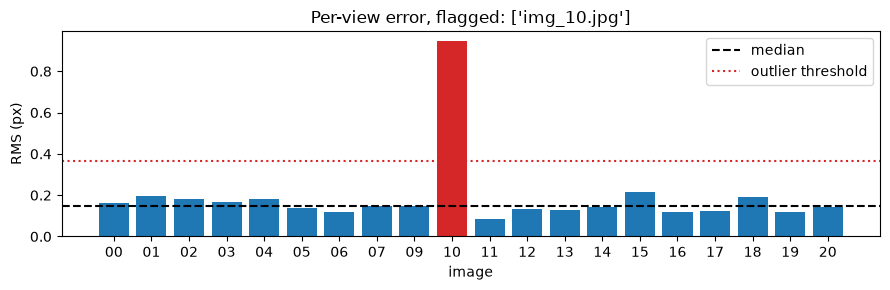

without ['img_10.jpg']: RMS 0.099 px


,estimated (outlier removed),true
fx,1999.56,2000.0
fy,2003.70,2004.0
cx,1212.07,1212.0
cy,885.96,886.0


In [4]:
bad = find_outlier_views(errs, names)
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar([n[4:6] for n in names], errs, color=["tab:red" if n in bad else "tab:blue" for n in names])
ax.axhline(np.median(errs), color="k", ls="--", label="median")
ax.axhline(max(2.5 * np.median(errs), 0.25), color="tab:red", ls=":", label="outlier threshold")
ax.set_xlabel("image"); ax.set_ylabel("RMS (px)"); ax.set_title(f"Per-view error, flagged: {bad}"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "per_view_errors.png", dpi=120); plt.show()

keep = [i for i, n in enumerate(names) if n not in bad]
names, img_pts = [names[i] for i in keep], [img_pts[i] for i in keep]
res = calibrate([objp] * len(names), img_pts, size, view_names=names)
print(f"without {bad}: RMS {res.rms:.3f} px")
k_table({"estimated (outlier removed)": res.K, "true": K_true})

**Outlier rule:** a view is flagged if its error exceeds `max(2.5 × median, 0.25 px)`. The **median** matters: a mean is pulled up by the bad view itself, which can then hide below its own threshold.
The flagged image (`img_10`) was taken **after the focus changed**, i.e. by a camera with a different $K$. No single model can fit it; that is why focus and zoom must be fixed during capture.
After removing it, the estimate is within ≈ 0.5 px of the true focal length and the RMS drops from 0.26 to 0.10 px.

## 3.2 Why the distortion model is needed

Reprojection residuals with the full model and with distortion switched off:

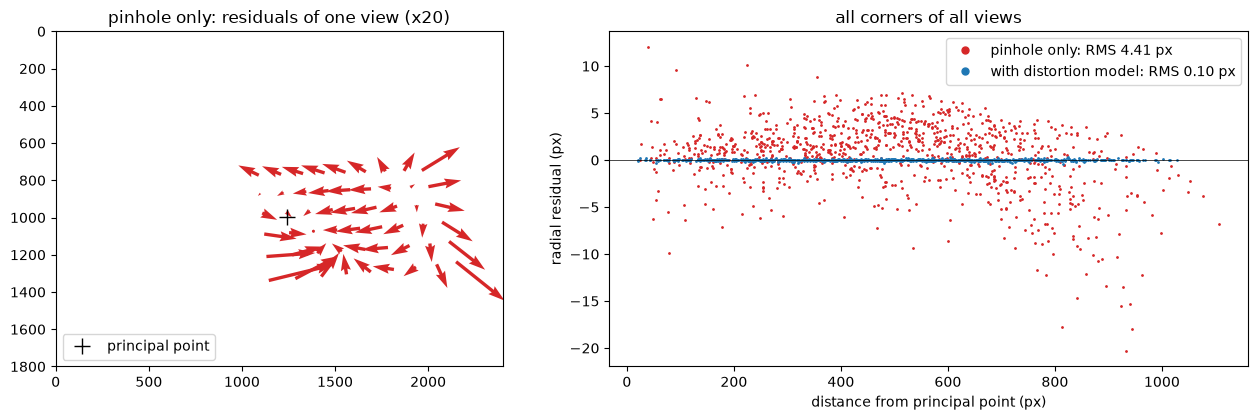

In [5]:
NO_DIST = cv2.CALIB_FIX_K1 | cv2.CALIB_FIX_K2 | cv2.CALIB_FIX_K3 | cv2.CALIB_ZERO_TANGENT_DIST
res_nodist = calibrate([objp] * len(names), img_pts, size, flags=NO_DIST)

def radial_residuals(r):
    """Distance of each corner from the principal point, and its residual along that direction."""
    rad, err = [], []
    for imgp, rv, tv in zip(img_pts, r.rvecs, r.tvecs):
        proj, _ = cv2.projectPoints(objp, rv, tv, r.K, r.dist)
        p, q = imgp.reshape(-1, 2), proj.reshape(-1, 2)
        v = p - r.K[:2, 2]
        dist_c = np.linalg.norm(v, axis=1)
        rad += list(dist_c)
        err += list(np.sum((p - q) * v / dist_c[:, None], axis=1))
    return np.array(rad), np.array(err)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw=dict(width_ratios=[1, 1.25]))

# left: residual vectors of one view without distortion model (x20)
i = names.index("img_19.jpg")
proj, _ = cv2.projectPoints(objp, res_nodist.rvecs[i], res_nodist.tvecs[i], res_nodist.K, res_nodist.dist)
p, q = img_pts[i].reshape(-1, 2), proj.reshape(-1, 2)
axes[0].quiver(p[:, 0], p[:, 1], *(q - p).T, angles="xy", scale_units="xy", scale=0.05, color="tab:red")
axes[0].plot(*res_nodist.K[:2, 2], "k+", ms=12, label="principal point")
axes[0].set_xlim(0, size[0]); axes[0].set_ylim(size[1], 0); axes[0].set_aspect("equal"); axes[0].legend(loc="lower left")
axes[0].set_title("pinhole only: residuals of one view (x20)")

# right: radial residual vs distance from the principal point, all views
for r, label, col in [(res_nodist, "pinhole only", "tab:red"), (res, "with distortion model", "tab:blue")]:
    rad, err = radial_residuals(r)
    axes[1].plot(rad, err, ".", ms=2, color=col, label=f"{label}: RMS {r.rms:.2f} px")
axes[1].axhline(0, color="k", lw=0.5); axes[1].legend(markerscale=5)
axes[1].set_xlabel("distance from principal point (px)"); axes[1].set_ylabel("radial residual (px)")
axes[1].set_title("all corners of all views")
fig.tight_layout(); fig.savefig(FIG / "residuals.png", dpi=110); plt.show()

With the distortion model the residuals are small and random (corner noise). Without it they are **large and systematic**: the radial component depends on the distance from the principal point (positive at mid radius, strongly negative towards the border). That is the signature of barrel distortion $k_1 r^2 + k_2 r^4 + k_3 r^6$, which a pinhole model can only partly absorb into $f$ (RMS 0.10 → 4.4 px).

## 3.3 Hold-out validation

A low training RMS can hide overfitting. Every 4th view is held out; for those views only the pose is estimated (`solvePnP`, $K$ fixed).

In [6]:
train_rms, ho = holdout_split(calibrate, img_pts, objp, size)
print(f"training RMS {train_rms:.3f} px | hold-out RMS {ho:.3f} px | ratio {ho / train_rms:.2f}")

training RMS 0.097 px | hold-out RMS 0.105 px | ratio 1.09


## 3.4 Scale ambiguity: what a wrong square size does

Calibrating the same detections with a 3× wrong square size (25 mm instead of 8.25 mm, a mistake I nearly made with an auto-scaled PDF):

In [7]:
res_wrong = calibrate([object_points(*PATTERN, 25.0 * 3)] * len(names), img_pts, size)
print(f"RMS: {res.rms:.4f} vs {res_wrong.rms:.4f} px  (identical)")
print(f"max |K difference|: {np.abs(res.K - res_wrong.K).max():.2e} px  (identical)")
print(f"distance to view 0: {np.linalg.norm(res.tvecs[0]):.0f} vs {np.linalg.norm(res_wrong.tvecs[0]):.0f} mm  (x3)")

RMS: 0.0992 vs 0.0992 px  (identical)
max |K difference|: 5.50e-08 px  (identical)
distance to view 0: 480 vs 1440 mm  (x3)


$K$, distortion and RMS are unchanged; only translations (and therefore every measurement) scale. No calibration metric can detect this, only measuring a known object can (notebook 5).

## 3.5 The webcam

In [8]:
SQUARE_MM = 8.24
objp_w = object_points(*PATTERN, SQUARE_MM)
names_w, pts_w, size_w = detect_folder(WEBCAM / "calib_1920x1080", "*.png")
res_w = calibrate([objp_w] * len(names_w), pts_w, size_w, view_names=names_w)
errs_w = per_view_errors(res_w, [objp_w] * len(names_w), pts_w)
print(f"{len(names_w)} frames, RMS {res_w.rms:.3f} px, flagged outliers: {find_outlier_views(errs_w, names_w)}")

train_w, ho_w = holdout_split(calibrate, pts_w, objp_w, size_w)
print(f"hold-out RMS {ho_w:.3f} px = {ho_w / train_w:.2f} x training RMS")

27 frames, RMS 0.268 px, flagged outliers: []
hold-out RMS 0.278 px = 1.05 x training RMS


**Do the six motion-blurred frames from notebook 2 matter?** The outlier rule did not flag them; recalibrating without them answers it directly:

In [9]:
from calib.detect import edge_sharpness
width = [edge_sharpness(cv2.imread(str(WEBCAM / "calib_1920x1080" / n), cv2.IMREAD_GRAYSCALE), PATTERN, c)
         for n, c in zip(names_w, pts_w)]
sharp = [i for i, w in enumerate(width) if w <= 1.5 * np.median(width)]
res_s = calibrate([objp_w] * len(sharp), [pts_w[i] for i in sharp], size_w)
train_s, ho_s = holdout_split(calibrate, [pts_w[i] for i in sharp], objp_w, size_w)

summary = k_table({f"all {len(names_w)} frames": res_w.K, f"{len(sharp)} sharp frames": res_s.K})
summary.loc["RMS (px)"] = [res_w.rms, res_s.rms]
summary.loc["hold-out / RMS"] = [ho_w / train_w, ho_s / train_s]
summary.round(3)

,all 27 frames,21 sharp frames
fx,1249.780,1246.780
fy,1249.050,1246.110
cx,925.840,924.180
cy,555.930,555.050
RMS (px),0.268,0.278
hold-out / RMS,1.049,0.832


In [10]:
from calib.io_yaml import save_calibration
save_calibration(ROOT / "calibration.yaml", res_w,
                 {"camera": "laptop webcam, index 0", "board": "9x6 checkerboard on phone screen",
                  "square_mm": SQUARE_MM, "n_views": len(names_w)})
print((ROOT / "calibration.yaml").read_text())

%YAML 1.2
---
camera_matrix: !!opencv-matrix
   rows: 3
   cols: 3
   dt: d
   data: [ 1249.7849602467377, 0., 925.83763952385971, 0.,
       1249.0466371298835, 555.93067339007632, 0., 0., 1. ]
dist_coeffs: !!opencv-matrix
   rows: 1
   cols: 5
   dt: d
   data: [ 0.055913479170572065, -0.22397741750942179,
       -2.1890280446954822e-05, 0.00013477905126677147,
       0.18119291447403155 ]
image_width: 1920
image_height: 1080
rms_px: 0.26759220835468672
date: "2026-10-17T22:37:55"
camera: "laptop webcam, index 0"
board: "9x6 checkerboard on phone screen"
square_mm: 8.2400000000000002
n_views: 27



| | Result | Target |
|---|---|---|
| RMS reprojection error | **0.27 px** | ≤ 0.5 px |
| Hold-out error | **1.05 × RMS** | ≤ 1.3 × RMS |
| Outlier views | none | — |

The calibration generalises to unseen views. The blurred frames shift $f$ by only a few pixels; I kept all 27 frames for the final calibration (`calibration.yaml`).